# Thử nghiệm transformer và phân tích theo khía cạnh

Notebook này trả lời góp ý của thầy: *model chưa đủ sâu, nên thêm keyword và transformer*.

| Phần | Câu hỏi |
|---|---|
| §2 | Mô hình hiện tại (M4) sai ở đâu và vì sao? |
| §3 | Fine-tune DistilBERT trên nhãn Steam có vượt model cũ không? |
| §4 | Từ khoá, TF-IDF + LR hay DistilBERT nhận khía cạnh tốt hơn? |
| §5 | Model học theo cặp *khía cạnh + câu* có chấm khen/chê đúng hơn không? |
| §6 | Ghép cả đường ống thì kết quả cuối ra sao? |
| §7 | Đầu ra: game nào bị chê ở khía cạnh nào? |
| §8 | Tổng kết |

**Giới hạn cần nói rõ:** nhãn khía cạnh và nhãn 500 review do Claude gán (quy tắc: `data/labels/QUY_TAC_GAN_NHAN.md`), **chưa có người kiểm tra độc lập**. Điểm khía cạnh cao chỉ có nghĩa model đọc giống người gán nhãn.

**Môi trường:** Keras 3 + keras-hub, nền PyTorch, GPU GTX 1650, vì TensorFlow bản mới không dùng được GPU trên Windows. M4 chạy bằng TensorFlow trong `data/labels/eval_A.py`, notebook chỉ đọc dự đoán đã lưu (`m4_preds.csv`).

**Xem tiến độ:** mở `data/labels/tien_do.txt`, hoặc xem dòng in ra dưới các ô đang chạy.

In [1]:
import gc, json, os, re, sys, time
os.environ["KERAS_BACKEND"] = "torch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import warnings
warnings.filterwarnings("ignore")
from collections import Counter
from pathlib import Path

import keras, keras_hub, torch
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from IPython.display import display
from keras import layers as L, ops
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from tokenizers import Tokenizer

LABELS = Path("data/labels")
sys.path.insert(0, str(LABELS))
from aspect_keywords import detect as kw_detect

SMOKE = os.environ.get("DAT_SMOKE") == "1"
SEEDS = [0, 1] if SMOKE else [0, 1, 2]
EPOCHS_SENT, EPOCHS_ASP, EPOCHS_POL = (1, 1, 1) if SMOKE else (3, 6, 5)
BS, MAXLEN = 16, 128
ASPECTS = ["GFX", "AUD", "PLAY", "STORY", "PERF", "PRICE", "ONLINE", "DEV"]
ASPECT_WORD = dict(GFX="graphics", AUD="audio", PLAY="gameplay", STORY="story", PERF="performance", PRICE="price", ONLINE="online", DEV="developer")
ASPECT_VI = dict(GFX="Đồ hoạ", AUD="Âm thanh", PLAY="Gameplay", STORY="Cốt truyện", PERF="Hiệu năng, lỗi", PRICE="Giá, trả phí", ONLINE="Online, cộng đồng", DEV="Nhà phát triển")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

PROGRESS = LABELS / ("tien_do_smoke.txt" if SMOKE else "tien_do.txt")
PROGRESS.write_text("", encoding="utf-8")
TRACK = {"total": 1, "done": 0, "t0": time.time()}

def tien_do(msg):
    pct = 100 * TRACK["done"] / max(TRACK["total"], 1)
    el = time.time() - TRACK["t0"]
    eta = el / TRACK["done"] * (TRACK["total"] - TRACK["done"]) / 60 if TRACK["done"] else float("nan")
    line = f"[{time.strftime('%H:%M:%S')}] tổng {pct:5.1f}% | còn khoảng {eta:5.0f} phút | {msg}"
    print(line, flush=True)
    with open(PROGRESS, "a", encoding="utf-8") as f:
        f.write(line + "\n")

class ProgressCB(keras.callbacks.Callback):
    def __init__(self, name, every=50):
        super().__init__(); self.name, self.every, self.last = name, every, 0
    def on_train_batch_end(self, batch, logs=None):
        TRACK["done"] += 1
        if batch and batch % self.every == 0:
            tien_do(f"{self.name}: batch {batch}, loss {logs.get('loss', 0):.3f}")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ", "| Keras", keras.__version__, keras.backend.backend(), "| chạy thử nhanh:", SMOKE)

GPU: NVIDIA GeForce GTX 1650 | Keras 3.15.1 torch | chạy thử nhanh: False


## 1. Dữ liệu

- **Review:** `steam_reviews_clean.csv`, chia y hệt `model.ipynb` (kịch bản A: chia ngẫu nhiên; kịch bản B: test trên game mới).
- **Nhãn review:** 500 review ngẫu nhiên trong tập test A, chỉ dùng để chấm.
- **Nhãn câu dùng để chấm:** 500 câu ngẫu nhiên và 110 câu chọn theo từ khoá cho khía cạnh hiếm, đều từ review tập test A. 110 câu thêm không dùng để đo độ phủ vì được chọn bằng chính từ khoá.
- **Nhãn câu dùng để train:** 1.500 câu từ review ngoài tập test A (900 ngẫu nhiên, 600 chọn theo từ khoá). Tách 15% theo review làm tập dev để chọn epoch và ngưỡng.

In [2]:
df = pd.read_csv("data/steam_reviews_clean.csv")
df["text_clean"] = df.text_clean.astype(str)
y = df.label.values
idx = np.arange(len(df))
trA, teA = train_test_split(idx, test_size=.15, stratify=y, random_state=0)
trA, vaA = train_test_split(trA, test_size=.15 / .85, stratify=y[trA], random_state=0)
trB, teB = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=0).split(idx, groups=df.app_id))
trB, vaB = train_test_split(trB, test_size=.15, stratify=y[trB], random_state=0)
SPLITS = {"A": (trA, vaA, teA), "B": (trB, vaB, teB)}

def parse(a):
    return {} if a == "NONE" else {x.split(":")[0]: x.split(":")[1] for x in a.split("|")}
def load(key, lab):
    d = pd.read_csv(LABELS / key).merge(pd.read_csv(LABELS / lab, keep_default_na=False), on="sample_id")
    d["gold"] = d.aspects.map(parse)
    return d
S_TEST, S_EXTRA, S_TRAIN = load("sentences_key.csv", "sentences_labels.csv"), load("sentences_extra_key.csv", "sentences_extra_labels.csv"), load("train_sentences_key.csv", "train_sentences_labels.csv")
assert not set(S_TRAIN.review_id) & set(df.review_id.values[teA]), "rò rỉ: câu train thuộc review test"
R = pd.read_csv(LABELS / "reviews_key.csv").merge(pd.read_csv(LABELS / "reviews_labels.csv", keep_default_na=False), on="sample_id")
pos = dict(zip(df.review_id, range(len(df))))
R["i"] = R.review_id.map(pos)
R["y"] = y[R.i]
m4 = pd.read_csv(LABELS / "m4_preds.csv", dtype={"id": str}).set_index("id").p
tr_i, dv_i = next(GroupShuffleSplit(n_splits=1, test_size=.15, random_state=0).split(S_TRAIN, groups=S_TRAIN.review_id))
if SMOKE:
    trA, vaA, teA = trA[:320], vaA[:100], teA
    trB, vaB = trB[:320], vaB[:100]
    SPLITS = {"A": (trA, vaA, teA), "B": (trB, vaB, teB)}
    tr_i = tr_i[:160]
print("Review train/val/test A:", len(trA), len(vaA), len(teA), "| B:", len(trB), len(vaB), len(teB))
print("Câu train/dev/test/thêm:", len(tr_i), len(dv_i), len(S_TEST), len(S_EXTRA))
cnt = pd.DataFrame({n: Counter(a for g in d.gold for a in g) for n, d in [("train", S_TRAIN), ("test ngẫu nhiên", S_TEST), ("thêm", S_EXTRA)]}).loc[ASPECTS].rename(index=ASPECT_VI)
display(cnt)

Review train/val/test A: 6979 1496 1496 | B: 6813 1203 1955
Câu train/dev/test/thêm: 1265 235 500 110


,train,test ngẫu nhiên,thêm
Đồ hoạ,194,10,33
Âm thanh,142,3,31
Gameplay,432,110,37
Cốt truyện,136,17,30
"Hiệu năng, lỗi",166,47,12
"Giá, trả phí",171,24,17
"Online, cộng đồng",146,61,3
Nhà phát triển,141,52,7


## 2. M4 hiện tại sai ở đâu?

Chấm M4 bằng nhãn Steam trên 500 review, rồi tách theo nhãn đọc tay. Khi M4 sai, phân loại nguyên nhân:

| Tình huống | Kết luận |
|---|---|
| Cảm xúc đọc tay **khớp** nhãn Steam | Model sai thật |
| Cảm xúc đọc tay **ngược** nhãn Steam | Nhãn nhiễu |
| Vừa khen vừa chê | Một nhãn không đủ mô tả |
| Không rõ | Thiếu ngữ cảnh |

In [3]:
def group_report(pm, name):
    d = R.assign(pm=pm, wrong=(pm >= .5).astype(int) != R.y)
    clear = d.sentiment.isin(["K", "C"]) & (d.kind == "BT")
    rows = []
    for n, m in [("Tất cả", d.sentiment != ""), ("Rõ ràng", clear), ("Còn lại", ~clear), ("Không rõ", d.sentiment == "U"), ("Vừa khen vừa chê", d.sentiment == "L"), ("Đùa, meme", d.kind == "DUA")]:
        s = d[m]
        rows.append({"nhóm": n, "số review": len(s), f"acc {name}": round(1 - s.wrong.mean(), 3), f"AUC {name}": round(roc_auc_score(s.y, s.pm), 3)})
    w = d[d.wrong]; kc = w.sentiment.isin(["K", "C"]); hum = (w.sentiment == "K").astype(int)
    cause = {"Model sai thật": int((kc & (hum == w.y)).sum()), "Nhãn nhiễu": int((kc & (hum != w.y)).sum()), "Vừa khen vừa chê": int((w.sentiment == "L").sum()), "Không rõ": int((w.sentiment == "U").sum())}
    return pd.DataFrame(rows).set_index("nhóm"), cause

PM4 = m4.loc[R.review_id.astype(str)].values
G_M4, CAUSE_M4 = group_report(PM4, "M4")
display(G_M4)
print("Nguyên nhân khi M4 sai:", CAUSE_M4)
kc = R[R.sentiment.isin(["K", "C"])]
print(f"Đọc tay khớp nhãn Steam: {((kc.sentiment == 'K').astype(int) == kc.y).mean():.3f} trên {len(kc)} review khen/chê rõ")

,số review,acc M4,AUC M4
nhóm,,,
Tất cả,500,0.806,0.887
Rõ ràng,365,0.868,0.942
Còn lại,135,0.637,0.672
Không rõ,71,0.606,0.628
Vừa khen vừa chê,25,0.600,0.649
"Đùa, meme",76,0.592,0.607


Nguyên nhân khi M4 sai: {'Model sai thật': 46, 'Nhãn nhiễu': 13, 'Vừa khen vừa chê': 10, 'Không rõ': 28}
Đọc tay khớp nhãn Steam: 0.948 trên 404 review khen/chê rõ


**Nhận xét** — M4 chấm tốt review rõ ràng (ROC-AUC 0,942) nhưng yếu rõ ở nhóm còn lại (0,672). Trong 97 lần đoán sai, 46 lần là model sai thật, 13 lần nhãn Steam ngược nội dung, 10 lần review vừa khen vừa chê, 28 lần không xác định được nếu thiếu ngữ cảnh. Như vậy khoảng một nửa số lỗi không xuất phát từ model, nhưng phần model sai thật vẫn đủ lớn để thử mô hình mạnh hơn. Cách phân loại này dựa trên nhãn đọc tay chưa được kiểm tra độc lập.

## 3. DistilBERT fine-tune cho khen/chê

**Làm gì:** lấy DistilBERT đã train sẵn, thêm một lớp ra và fine-tune trên nhãn Steam. Review dài cắt đầu + cuối còn 128 token, vì kết luận thường nằm ở cuối.

**Vì sao đây là "sâu hơn":** M4 chỉ đếm từ. DistilBERT có 6 lớp transformer đọc từ trong ngữ cảnh cả câu, và được học sẵn trên lượng văn bản lớn nên phù hợp khi dữ liệu chỉ có khoảng 7.000 review.

**Tiêu chí đã đề xuất trước khi chạy:** coi là hiệu quả khi ROC-AUC tăng từ 0,01 trở lên so với baseline ở **cả hai kịch bản** và lớn hơn dao động giữa các seed. Mỗi kịch bản chạy 3 seed; baseline là TF-IDF + meta + LR tính lại ngay dưới đây.

In [4]:
tok = Tokenizer.from_pretrained("distilbert/distilbert-base-uncased")
CLS, SEP = tok.token_to_id("[CLS]"), tok.token_to_id("[SEP]")

def encode(texts, prefix=None):
    """prefix: từ khía cạnh đặt trước câu, dạng [CLS] khía cạnh [SEP] câu [SEP]."""
    ids = np.zeros((len(texts), MAXLEN), "int32"); mask = np.zeros((len(texts), MAXLEN), "int32")
    pre = [] if prefix is None else None
    enc = tok.encode_batch([str(t) for t in texts], add_special_tokens=False)
    pref = None if prefix is None else [tok.encode(p, add_special_tokens=False).ids for p in prefix]
    for i, e in enumerate(enc):
        head = [CLS] + ([] if pref is None else pref[i] + [SEP])
        room = MAXLEN - len(head) - 1
        t = e.ids if len(e.ids) <= room else e.ids[:room // 2] + e.ids[-(room - room // 2):]
        t = head + t + [SEP]
        ids[i, :len(t)] = t; mask[i, :len(t)] = 1
    return {"token_ids": ids, "padding_mask": mask}

class MaskMean(L.Layer):
    def call(self, x, m):
        m = ops.cast(m, x.dtype)[..., None]
        return ops.sum(x * m, 1) / (ops.sum(m, 1) + 1e-6)

def build(n_out, steps, lr=2e-5, init=None):
    b = keras_hub.models.DistilBertBackbone.from_preset("hf://distilbert/distilbert-base-uncased")
    if init is not None:
        b.set_weights(init)
    ids = keras.Input((MAXLEN,), dtype="int32", name="token_ids")
    mask = keras.Input((MAXLEN,), dtype="int32", name="padding_mask")
    x = L.Dropout(.2)(MaskMean()(b({"token_ids": ids, "padding_mask": mask}), mask))
    m = keras.Model([ids, mask], L.Dense(n_out, activation="sigmoid")(x))
    sch = keras.optimizers.schedules.CosineDecay(0., steps, warmup_target=lr, warmup_steps=max(1, int(.1 * steps)))
    m.compile(keras.optimizers.AdamW(sch, weight_decay=.01, clipnorm=1.), "binary_crossentropy")
    return m, b

def finetune(name, Xtr, ytr, Xdv, score, epochs, seed, n_out=1, lr=2e-5, init=None):
    """Train từng epoch, chấm trên dev bằng hàm score, giữ trọng số của epoch tốt nhất."""
    keras.utils.set_random_seed(seed)
    steps = epochs * (len(ytr) // BS + 1)
    m, b = build(n_out, steps, lr, init)
    best, hist, t0 = (-1, 0, None), [], time.time()
    for ep in range(epochs):
        h = m.fit(Xtr, ytr, batch_size=BS, epochs=1, verbose=0, callbacks=[ProgressCB(f"{name} epoch {ep + 1}/{epochs}")])
        a = score(m.predict(Xdv, batch_size=32, verbose=0))
        hist.append((ep + 1, round(h.history["loss"][0], 4), round(a, 4)))
        tien_do(f"{name} xong epoch {ep + 1}/{epochs}: điểm dev {a:.4f}")
        if a > best[0]:
            best = (a, ep + 1, [w.copy() for w in m.get_weights()])
    m.set_weights(best[2])
    return m, b, dict(name=name, best_epoch=best[1], dev=round(best[0], 4), seconds=round(time.time() - t0), hist=hist)

def free():
    gc.collect(); torch.cuda.empty_cache()

def predict_with(weights, n_out, X, batch_size=64):
    # dựng lại model từ trọng số đã lưu, dự đoán rồi giải phóng GPU
    m, b = build(n_out, 10)
    m.set_weights(weights)
    p = m.predict(X, batch_size=batch_size, verbose=0)
    del m, b; free()
    return p

# ước lượng tổng số batch để báo % và thời gian còn lại
TRACK["total"] = (sum(len(SPLITS[k][0]) // BS + 1 for k in "AB") * EPOCHS_SENT
                  + (len(tr_i) // BS + 1) * EPOCHS_ASP
                  + (sum(len(g) for g in S_TRAIN.iloc[tr_i].gold) // BS + 1) * EPOCHS_POL) * len(SEEDS)
TRACK["t0"] = time.time()
print("Tổng số batch dự kiến:", TRACK["total"])

Tổng số batch dự kiến: 10407


In [5]:
def tfidf_lr(k):
    tr, va, te = SPLITS[k]
    meta = df.assign(log_len=np.log1p(df.word_count), has_q=df.text_clean.str.contains("?", regex=False).astype(int))[["log_len", "has_q"]].values
    sc = StandardScaler().fit(meta[tr])
    w = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
    c = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=80000, sublinear_tf=True)
    txt = df.text_clean.values
    X = lambda ix, fit=False: hstack([w.fit_transform(txt[ix]) if fit else w.transform(txt[ix]), c.fit_transform(txt[ix]) if fit else c.transform(txt[ix]), sc.transform(meta[ix])]).tocsr()
    Xtr, Xva, Xte = X(tr, True), X(va), X(te)
    best = max((roc_auc_score(y[va], LogisticRegression(C=C_, max_iter=3000).fit(Xtr, y[tr]).predict_proba(Xva)[:, 1]), C_) for C_ in (.5, 1, 2, 4))
    return LogisticRegression(C=best[1], max_iter=3000).fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]

tien_do("Baseline TF-IDF + LR")
P_LR = {k: tfidf_lr(k) for k in "AB"}
print({k: round(roc_auc_score(y[SPLITS[k][2]], P_LR[k]), 4) for k in "AB"})

[01:06:55] tổng   0.0% | còn khoảng   nan phút | Baseline TF-IDF + LR


{'A': 0.9036, 'B': 0.9058}


In [6]:
ENC = encode(df.text_clean.values)
take = lambda d, ix: {k: v[ix] for k, v in d.items()}
ALL_S = pd.concat([S_TEST, S_EXTRA], ignore_index=True)
ENC_S = encode(ALL_S.sentence.values)
SENT_RES, P_SENT, P_SENT_S, P_R500, LOGS, STEAM_INIT = [], {"A": [], "B": []}, [], [], [], None
for k in "AB":
    tr, va, te = SPLITS[k]
    for s in SEEDS:
        name = f"Khen/chê kịch bản {k}, seed {s}"
        tien_do(f"BẮT ĐẦU {name}")
        m, b, log = finetune(name, take(ENC, tr), y[tr].astype("float32"), take(ENC, va), lambda p: roc_auc_score(y[va], p.ravel()), EPOCHS_SENT, s)
        p = m.predict(take(ENC, te), batch_size=32, verbose=0).ravel()
        P_SENT[k].append(p)
        SENT_RES.append(dict(kịch_bản=k, seed=s, AUC=round(roc_auc_score(y[te], p), 4), acc=round(accuracy_score(y[te], p >= .5), 4), epoch_tốt=log["best_epoch"], giây=log["seconds"], vram_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2)))
        LOGS.append(log)
        tien_do(f"XONG {name}: AUC test {SENT_RES[-1]['AUC']}")
        if k == "A":
            P_R500.append(m.predict(take(ENC, R.i.values), batch_size=32, verbose=0).ravel())
            P_SENT_S.append(m.predict(ENC_S, batch_size=32, verbose=0).ravel())
            if s == SEEDS[0]:
                STEAM_INIT = [w.copy() for w in b.get_weights()]
        del m, b; free()
SR = pd.DataFrame(SENT_RES); display(SR)
SR.to_csv(LABELS / ("ket_qua_B_sentiment_smoke.csv" if SMOKE else "ket_qua_B_sentiment.csv"), index=False)

[01:07:16] tổng   0.0% | còn khoảng   nan phút | BẮT ĐẦU Khen/chê kịch bản A, seed 0


[01:07:41] tổng   0.5% | còn khoảng   157 phút | Khen/chê kịch bản A, seed 0 epoch 1/3: batch 50, loss 0.695


[01:08:02] tổng   1.0% | còn khoảng   115 phút | Khen/chê kịch bản A, seed 0 epoch 1/3: batch 100, loss 0.656


[01:08:23] tổng   1.5% | còn khoảng   100 phút | Khen/chê kịch bản A, seed 0 epoch 1/3: batch 150, loss 0.593


[01:08:44] tổng   1.9% | còn khoảng    93 phút | Khen/chê kịch bản A, seed 0 epoch 1/3: batch 200, loss 0.556


[01:09:06] tổng   2.4% | còn khoảng    88 phút | Khen/chê kịch bản A, seed 0 epoch 1/3: batch 250, loss 0.521


... (165 outputs left out)

[15:39:26] tổng  74.4% | còn khoảng   300 phút | Khen/chê kịch bản B, seed 2 epoch 3/3: batch 400, loss 0.168


[15:39:46] tổng  74.6% | còn khoảng   297 phút | Khen/chê kịch bản B, seed 2 xong epoch 3/3: điểm dev 0.9358


[15:40:01] tổng  74.6% | còn khoảng   297 phút | XONG Khen/chê kịch bản B, seed 2: AUC test 0.9293


,kịch_bản,seed,AUC,acc,epoch_tốt,giây,vram_gb
0,A,0,0.9374,0.8610,2,592,2.17
1,A,1,0.9347,0.8563,2,591,2.17
2,A,2,0.9385,0.8596,2,591,2.17
3,B,0,0.9319,0.8547,2,619,2.17
4,B,1,0.9299,0.8568,3,812,2.17
5,B,2,0.9293,0.8496,3,49027,2.17


,LR,DistilBERT trung bình,độ lệch giữa seed,chênh lệch,DistilBERT gộp seed,CI 95% của gộp seed - LR,"đạt tiêu chí 0,01"
kịch bản,,,,,,,
A,0.9036,0.9368,0.0016,0.0332,0.9398,+0.026 đến +0.047,True
B,0.9058,0.9304,0.0011,0.0246,0.9327,+0.017 đến +0.037,True


Tham chiếu từ model.ipynb (ROC-AUC A/B): M4 0,89/0,89; M5 ensemble 0,90/0,91
M4 trên tập test A đọc lại từ file: 0.8911


,số review,acc M4,AUC M4,acc DistilBERT,AUC DistilBERT
nhóm,,,,,
Tất cả,500,0.806,0.887,0.862,0.931
Rõ ràng,365,0.868,0.942,0.915,0.968
Còn lại,135,0.637,0.672,0.719,0.758
Không rõ,71,0.606,0.628,0.690,0.732
Vừa khen vừa chê,25,0.600,0.649,0.720,0.727
"Đùa, meme",76,0.592,0.607,0.684,0.704


,M4,DistilBERT
Model sai thật,46,26
Nhãn nhiễu,13,14
Vừa khen vừa chê,10,7
Không rõ,28,22


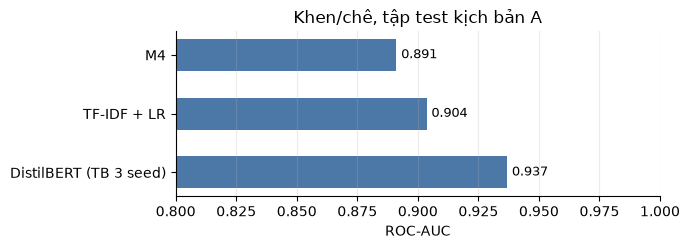

In [7]:
def boot_delta(yt, a, b, n=2000, seed=0):
    """Khoảng tin cậy 95% của chênh lệch ROC-AUC a - b, lấy mẫu lại cùng một tập test."""
    r = np.random.default_rng(seed); ds = []
    for _ in range(n):
        i = r.integers(0, len(yt), len(yt))
        if yt[i].min() != yt[i].max():
            ds.append(roc_auc_score(yt[i], a[i]) - roc_auc_score(yt[i], b[i]))
    return np.percentile(ds, [2.5, 97.5])

rows = []
for k in "AB":
    te = SPLITS[k][2]
    au = [roc_auc_score(y[te], p) for p in P_SENT[k]]
    lr = roc_auc_score(y[te], P_LR[k])
    ens = np.mean(P_SENT[k], 0)
    lo, hi = boot_delta(y[te], ens, P_LR[k])
    rows.append({"kịch bản": k, "LR": round(lr, 4), "DistilBERT trung bình": round(np.mean(au), 4), "độ lệch giữa seed": round(np.std(au), 4), "chênh lệch": round(np.mean(au) - lr, 4),
                 "DistilBERT gộp seed": round(roc_auc_score(y[te], ens), 4), "CI 95% của gộp seed - LR": f"{lo:+.3f} đến {hi:+.3f}", "đạt tiêu chí 0,01": bool(np.mean(au) - lr >= .01 and np.mean(au) - lr > np.std(au))})
CMP = pd.DataFrame(rows).set_index("kịch bản"); display(CMP)
print("Tham chiếu từ model.ipynb (ROC-AUC A/B): M4 0,89/0,89; M5 ensemble 0,90/0,91")
print("M4 trên tập test A đọc lại từ file:", round(roc_auc_score(y[teA], m4.loc[df.review_id.values[teA].astype(str)].values), 4))

G_DB, CAUSE_DB = group_report(P_R500[0], "DistilBERT")
display(G_M4.join(G_DB.drop(columns="số review")))
display(pd.DataFrame({"M4": CAUSE_M4, "DistilBERT": CAUSE_DB}))

fig, ax = plt.subplots(figsize=(7, 2.6))
names, vals = ["M4", "TF-IDF + LR", "DistilBERT (TB 3 seed)"], [roc_auc_score(y[teA], m4.loc[df.review_id.values[teA].astype(str)].values), roc_auc_score(y[teA], P_LR["A"]), np.mean([roc_auc_score(y[teA], p) for p in P_SENT["A"]])]
ax.barh(names[::-1], vals[::-1], color="#4C78A8", height=.55)
for i, v in enumerate(vals[::-1]):
    ax.text(v + .002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(xlim=(.8, 1), xlabel="ROC-AUC", title="Khen/chê, tập test kịch bản A"); ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

**Nhận xét** — DistilBERT đạt tiêu chí ở cả hai kịch bản: ROC-AUC trung bình 0,937 (A) và 0,930 (B), so với LR 0,904 và 0,906. Mức tăng 0,033 và 0,025 lớn hơn nhiều so với dao động giữa các seed (khoảng 0,001–0,002); khoảng tin cậy 95% của bản gộp seed so với LR không chứa 0. Trên 500 review đọc tay, số lần model sai thật giảm từ 46 xuống 26, còn lỗi do nhãn nhiễu gần như giữ nguyên (13 và 14). Kết quả này hợp lí: mô hình tốt hơn sửa được lỗi đọc hiểu nhưng không sửa được nhãn.

## 4. Nhận khía cạnh: từ khoá, TF-IDF + LR, DistilBERT

**Làm gì:** bài toán đa nhãn, mỗi câu có thể thuộc nhiều trong 8 khía cạnh. Chấm trên 500 câu ngẫu nhiên.

- **Từ khoá:** từ điển viết tay, không học gì.
- **TF-IDF + LR:** mốc so sánh công bằng cho model có học, tránh việc transformer chỉ thắng một đối thủ yếu.
- **DistilBERT:** fine-tune trên 1.265 câu, chạy 3 seed.

Ngưỡng từng khía cạnh được chọn trên tập dev, không dùng tập test.

[15:40:19] tổng  74.6% | còn khoảng   297 phút | BẮT ĐẦU Nhận khía cạnh, seed 0


[15:40:43] tổng  75.1% | còn khoảng   289 phút | Nhận khía cạnh, seed 0 epoch 1/6: batch 50, loss 0.473


[15:40:58] tổng  75.4% | còn khoảng   285 phút | Nhận khía cạnh, seed 0 xong epoch 1/6: điểm dev 0.3636


[15:41:20] tổng  75.9% | còn khoảng   278 phút | Nhận khía cạnh, seed 0 epoch 2/6: batch 50, loss 0.249


[15:41:34] tổng  76.2% | còn khoảng   274 phút | Nhận khía cạnh, seed 0 xong epoch 2/6: điểm dev 0.6070


[15:41:57] tổng  76.7% | còn khoảng   266 phút | Nhận khía cạnh, seed 0 epoch 3/6: batch 50, loss 0.153


... (35 outputs left out)

[15:51:35] tổng  88.5% | còn khoảng   115 phút | XONG Nhận khía cạnh, seed 2: micro F1 test 0.628


,precision,recall,micro_f1,macro_f1
Từ khoá,0.762,0.552,0.640,0.663
TF-IDF + LR,0.518,0.540,0.529,0.549
DistilBERT (TB seed),0.559,0.697,0.616,0.654


Độ lệch micro F1 giữa seed: 0.0095


,số câu thật,Từ khoá,TF-IDF + LR,DistilBERT seed đầu
Đồ hoạ,10,0.80,0.59,0.67
Âm thanh,3,0.57,0.50,1.00
Gameplay,110,0.50,0.52,0.59
Cốt truyện,17,0.72,0.69,0.69
"Hiệu năng, lỗi",47,0.72,0.54,0.65
"Giá, trả phí",24,0.62,0.58,0.51
"Online, cộng đồng",61,0.74,0.53,0.65
Nhà phát triển,52,0.63,0.46,0.55


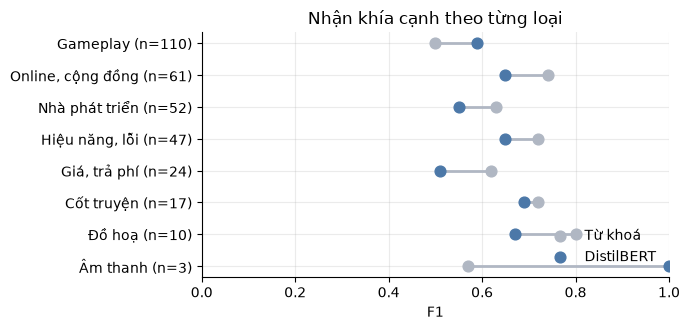

In [8]:
def Y_of(d):
    return np.array([[a in g for a in ASPECTS] for g in d.gold], "float32")
Ytr, Ydv, Yte = Y_of(S_TRAIN.iloc[tr_i]), Y_of(S_TRAIN.iloc[dv_i]), Y_of(S_TEST)

def prf(Y, H):
    Y, H = Y.astype(bool), H.astype(bool)
    tp, fp, fn = (Y & H).sum(0), (~Y & H).sum(0), (Y & ~H).sum(0)
    f = lambda t, p, n: 2 * t / max(2 * t + p + n, 1)
    per = {ASPECTS[i]: (tp[i] / max(tp[i] + fp[i], 1), tp[i] / max(tp[i] + fn[i], 1), f(tp[i], fp[i], fn[i])) for i in range(Y.shape[1])}
    return dict(precision=tp.sum() / max(tp.sum() + fp.sum(), 1), recall=tp.sum() / max(tp.sum() + fn.sum(), 1), micro_f1=f(tp.sum(), fp.sum(), fn.sum()), macro_f1=np.mean([v[2] for v in per.values()])), per

def tune_thr(Y, P):
    grid = np.arange(.1, .91, .05); t = []
    for j in range(Y.shape[1]):
        t.append(max(grid, key=lambda g: (prf(Y[:, [j]], P[:, [j]] >= g)[0]["micro_f1"], -abs(g - .5))))
    return np.array(t)

H_KW = np.array([[a in kw_detect(s) for a in ASPECTS] for s in S_TEST.sentence])
tv = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_t, Xdv_t, Xte_t = tv.fit_transform(S_TRAIN.sentence.values[tr_i]), tv.transform(S_TRAIN.sentence.values[dv_i]), tv.transform(S_TEST.sentence)
Pd_lr, Pt_lr = [], []
for j in range(len(ASPECTS)):
    c = LogisticRegression(C=4, max_iter=2000, class_weight="balanced").fit(Xtr_t, Ytr[:, j])
    Pd_lr.append(c.predict_proba(Xdv_t)[:, 1]); Pt_lr.append(c.predict_proba(Xte_t)[:, 1])
Pd_lr, Pt_lr = np.array(Pd_lr).T, np.array(Pt_lr).T
H_LR = Pt_lr >= tune_thr(Ydv, Pd_lr)

Etr, Edv, Ete = encode(S_TRAIN.sentence.values[tr_i]), encode(S_TRAIN.sentence.values[dv_i]), encode(S_TEST.sentence.values)
P_ASP, H_DB, ASP_THR, ASP_RES = [], [], [], []
ASP_MODELS = {}
for s in SEEDS:
    name = f"Nhận khía cạnh, seed {s}"
    tien_do(f"BẮT ĐẦU {name}")
    m, b, log = finetune(name, Etr, Ytr, Edv, lambda p: prf(Ydv, p >= .5)[0]["micro_f1"], EPOCHS_ASP, s, n_out=8, lr=3e-5)
    pd_ = m.predict(Edv, batch_size=32, verbose=0); pt = m.predict(Ete, batch_size=32, verbose=0)
    thr = tune_thr(Ydv, pd_)
    H = pt >= thr
    P_ASP.append(pt); H_DB.append(H); ASP_THR.append(thr)
    ASP_RES.append(prf(Yte, H)[0]); LOGS.append(log)
    tien_do(f"XONG {name}: micro F1 test {ASP_RES[-1]['micro_f1']:.3f}")
    if s == SEEDS[0]:
        ASP_MODELS["w"] = [w.copy() for w in m.get_weights()]   # giữ trọng số ở RAM, GPU 4 GB không chứa nổi nhiều model
    del m, b; free()
rows = {"Từ khoá": prf(Yte, H_KW)[0], "TF-IDF + LR": prf(Yte, H_LR)[0], "DistilBERT (TB seed)": pd.DataFrame(ASP_RES).mean().to_dict()}
DET = pd.DataFrame(rows).T.round(3); display(DET)
print("Độ lệch micro F1 giữa seed:", round(pd.DataFrame(ASP_RES).micro_f1.std(ddof=0), 4))
per = pd.DataFrame({n: {ASPECT_VI[a]: round(v[2], 2) for a, v in prf(Yte, h)[1].items()} for n, h in [("Từ khoá", H_KW), ("TF-IDF + LR", H_LR), ("DistilBERT seed đầu", H_DB[0])]})
per.insert(0, "số câu thật", [int(Yte[:, j].sum()) for j in range(8)])
display(per)

fig, ax = plt.subplots(figsize=(7, 3.4))
pp = per.sort_values("số câu thật")
yy = np.arange(len(pp))
ax.scatter(pp["Từ khoá"], yy, color="#B0B7C3", s=60, label="Từ khoá", zorder=3)
ax.scatter(pp["DistilBERT seed đầu"], yy, color="#4C78A8", s=60, label="DistilBERT", zorder=3)
for i, (a, b_) in enumerate(zip(pp["Từ khoá"], pp["DistilBERT seed đầu"])):
    ax.plot([a, b_], [i, i], color="#B0B7C3", lw=2, zorder=2)
ax.set_yticks(yy, [f"{n} (n={c})" for n, c in zip(pp.index, pp["số câu thật"])]); ax.set(xlim=(0, 1), xlabel="F1", title="Nhận khía cạnh theo từng loại"); ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Nhận xét** — Trên 500 câu ngẫu nhiên, DistilBERT (micro F1 0,616) chưa vượt từ khoá (0,640): tìm được nhiều hơn (recall 0,70 so với 0,55) nhưng gán thừa nhiều hơn (precision 0,56 so với 0,76). TF-IDF + LR thấp nhất (0,529). Có hai điểm cần lưu ý: từ khoá được viết sau khi đã đọc tập test nên có lợi thế; và ngưỡng được chọn trên tập dev có nhiều câu chọn theo từ khoá, khác phân phối với tập test ngẫu nhiên, nên có thể làm model gán thừa. Điểm dev (khoảng 0,72) cao hơn test (0,62) phù hợp với giải thích này. Phần này được kiểm tra tiếp trong `aspect_model_run2.ipynb`.

## 5. Chấm khen/chê theo từng khía cạnh

**Làm gì:** so ba cách trên cùng các cặp (câu, khía cạnh) có nhãn Khen hoặc Chê, gồm 500 câu ngẫu nhiên và 110 câu thêm.

- **M4 cả câu:** model cũ cho một điểm cho cả câu.
- **DistilBERT cả câu:** model §3 cho một điểm cho cả câu.
- **DistilBERT theo cặp:** đầu vào `[CLS] khía cạnh [SEP] câu [SEP]`, bắt đầu từ trọng số đã học nhãn Steam ở §3, rồi fine-tune trên các cặp đã gán. Chỉ cách này có thể cho hai khía cạnh trong cùng một câu hai kết quả khác nhau.

Điều đáng xem nhất là nhóm **câu có khía cạnh trái cảm xúc**, nhưng nhóm này ít mẫu nên chỉ để tham khảo.

In [9]:
def pairs(d):
    rows = []
    for i, g in zip(d.index, d.gold):
        v = {x for x in g.values() if x in "KC"}
        for a, s in g.items():
            if s in "KC":
                rows.append((i, a, int(s == "K"), len(g) > 1, len(v) > 1))
    return pd.DataFrame(rows, columns=["i", "a", "y", "multi", "conflict"])

Ptr, Pdv = pairs(S_TRAIN.iloc[tr_i]), pairs(S_TRAIN.iloc[dv_i])
Pte = pairs(ALL_S)
print("Cặp train/dev/test:", len(Ptr), len(Pdv), len(Pte), "| % Khen train:", round(Ptr.y.mean() * 100, 1), "| % Khen test:", round(Pte.y.mean() * 100, 1))
enc_pair = lambda d, P: encode(d.loc[P.i].sentence.values, [ASPECT_WORD[a] for a in P.a])
Etr_p, Edv_p, Ete_p = enc_pair(S_TRAIN, Ptr), enc_pair(S_TRAIN, Pdv), enc_pair(ALL_S, Pte)
P_POL, POL_MODELS = [], {}
for s in SEEDS:
    name = f"Khen/chê theo cặp, seed {s}"
    tien_do(f"BẮT ĐẦU {name}")
    m, b, log = finetune(name, Etr_p, Ptr.y.values.astype("float32"), Edv_p, lambda p: roc_auc_score(Pdv.y, p.ravel()), EPOCHS_POL, s, lr=2e-5, init=STEAM_INIT)
    P_POL.append(m.predict(Ete_p, batch_size=32, verbose=0).ravel()); LOGS.append(log)
    tien_do(f"XONG {name}: acc test {accuracy_score(Pte.y, P_POL[-1] >= .5):.3f}")
    if s == SEEDS[0]:
        POL_MODELS["w"] = [w.copy() for w in m.get_weights()]
    del m, b; free()

M4_S = m4.loc[ALL_S.sample_id].values
def pol_table():
    subs = [("Tất cả", np.ones(len(Pte), bool)), ("Câu 1 khía cạnh", ~Pte.multi), ("Nhiều khía cạnh, cùng cảm xúc", Pte.multi & ~Pte.conflict), ("Nhiều khía cạnh, trái cảm xúc", Pte.conflict), ("Thật sự là Khen", Pte.y == 1), ("Thật sự là Chê", Pte.y == 0)]
    rows = []
    for n, f in subs:
        f = np.asarray(f); yy = Pte.y.values[f]
        acc = lambda p: accuracy_score(yy, p[f] >= .5)
        rows.append({"nhóm": n, "số cặp": int(f.sum()), "M4 cả câu": round(acc(M4_S[Pte.i.values]), 3), "DistilBERT cả câu": round(np.mean([acc(p[Pte.i.values]) for p in P_SENT_S]), 3), "DistilBERT theo cặp": round(np.mean([acc(p) for p in P_POL]), 3)})
    return pd.DataFrame(rows).set_index("nhóm")
POL = pol_table(); display(POL)
print("Luôn đoán Chê đạt:", round((Pte.y == 0).mean(), 3))
print("AUC:", {"M4": round(roc_auc_score(Pte.y, M4_S[Pte.i.values]), 3), "DistilBERT cả câu": round(np.mean([roc_auc_score(Pte.y, p[Pte.i.values]) for p in P_SENT_S]), 3), "Theo cặp": round(np.mean([roc_auc_score(Pte.y, p) for p in P_POL]), 3), "độ lệch cặp": round(np.std([roc_auc_score(Pte.y, p) for p in P_POL]), 4)})
ex = Pte.assign(p=P_POL[0], s=ALL_S.loc[Pte.i, "sentence"].values)[Pte.conflict.values]
pd.set_option("display.max_colwidth", 140)
display(ex.assign(đoán=np.where(ex.p >= .5, "Khen", "Chê"), thật=np.where(ex.y == 1, "Khen", "Chê"))[["a", "thật", "đoán", "s"]].head(14))

Cặp train/dev/test: 1133 227 445 | % Khen train: 39.3 | % Khen test: 33.3
[15:51:36] tổng  88.5% | còn khoảng   115 phút | BẮT ĐẦU Khen/chê theo cặp, seed 0


[15:52:00] tổng  89.0% | còn khoảng   110 phút | Khen/chê theo cặp, seed 0 epoch 1/5: batch 50, loss 0.275


[15:52:10] tổng  89.2% | còn khoảng   108 phút | Khen/chê theo cặp, seed 0 xong epoch 1/5: điểm dev 0.9911


[15:52:32] tổng  89.6% | còn khoảng   102 phút | Khen/chê theo cặp, seed 0 epoch 2/5: batch 50, loss 0.175


[15:52:43] tổng  89.8% | còn khoảng   100 phút | Khen/chê theo cặp, seed 0 xong epoch 2/5: điểm dev 0.9922


[15:53:05] tổng  90.3% | còn khoảng    95 phút | Khen/chê theo cặp, seed 0 epoch 3/5: batch 50, loss 0.114


... (29 outputs left out)

[15:59:53] tổng  98.7% | còn khoảng    12 phút | XONG Khen/chê theo cặp, seed 2: acc test 0.881


,số cặp,M4 cả câu,DistilBERT cả câu,DistilBERT theo cặp
nhóm,,,,
Tất cả,445,0.753,0.863,0.894
Câu 1 khía cạnh,264,0.727,0.857,0.899
"Nhiều khía cạnh, cùng cảm xúc",153,0.837,0.932,0.948
"Nhiều khía cạnh, trái cảm xúc",28,0.536,0.536,0.548
Thật sự là Khen,148,0.919,0.894,0.860
Thật sự là Chê,297,0.670,0.847,0.910


Luôn đoán Chê đạt: 0.667
AUC: {'M4': 0.903, 'DistilBERT cả câu': np.float64(0.94), 'Theo cặp': np.float64(0.959), 'độ lệch cặp': np.float64(0.0009)}


,a,thật,đoán,s
45,GFX,Khen,Chê,its a shame to call this 1.0 the game looks beautiful but there so many bugs and it shouldve never pass the quality control
46,PERF,Chê,Chê,its a shame to call this 1.0 the game looks beautiful but there so many bugs and it shouldve never pass the quality control
94,PLAY,Chê,Chê,"the game is mid, couldnt figure out how to switch off the blue truck and crashed it and didnt know how to respawn it but over than that ..."
95,GFX,Khen,Chê,"the game is mid, couldnt figure out how to switch off the blue truck and crashed it and didnt know how to respawn it but over than that ..."
113,PLAY,Khen,Chê,"I loved the first edition and the system in this one is pretty good too, but the creator is running it down to a <censored>"
114,DEV,Chê,Chê,"I loved the first edition and the system in this one is pretty good too, but the creator is running it down to a <censored>"
245,STORY,Khen,Chê,I have around 8k hours on console before i came to pc and I can say this game used to be awesome but like the only reason i play anymore...
246,PLAY,Chê,Chê,I have around 8k hours on console before i came to pc and I can say this game used to be awesome but like the only reason i play anymore...
258,PLAY,Khen,Chê,"Mediocre game, fun extraction content, but holy crap do they have a twisted way of looking at cheating."
259,ONLINE,Chê,Chê,"Mediocre game, fun extraction content, but holy crap do they have a twisted way of looking at cheating."


**Nhận xét** — DistilBERT theo cặp đạt độ chính xác 0,894 và ROC-AUC 0,959, cao hơn DistilBERT chấm cả câu (0,863 và 0,940) và M4 (0,753 và 0,903). Tuy nhiên nhóm câu trái cảm xúc chưa được cải thiện (0,548 so với 0,536), với chỉ 28 cặp nên chưa đủ để kết luận. Điểm dev khoảng 0,99 cao bất thường, nhiều khả năng do rò rỉ: trọng số khởi tạo đã học nhãn Steam trên chính các review chứa câu dev. Tập test không bị ảnh hưởng, nhưng việc chọn epoch không đáng tin; `aspect_model_run2.ipynb` xử lí lại điểm này.

## 6. Cả đường ống

Chấm trên 500 câu ngẫu nhiên: một kết quả chỉ tính đúng khi đúng **cả khía cạnh lẫn cảm xúc**. Khía cạnh đọc tay là Trung tính hoặc Không rõ thì bỏ qua, không tính đúng hay sai.

| Phương án | Nhận khía cạnh | Chấm khen/chê |
|---|---|---|
| Cũ | Từ khoá | M4 cả câu |
| A | Từ khoá | DistilBERT cả câu (nhãn Steam) |
| B | DistilBERT | DistilBERT theo cặp |

In [10]:
def pipe_f1(H, polarity):
    tp = fp = fn = 0
    for i, g in enumerate(S_TEST.gold):
        gold = {(a, v) for a, v in g.items() if v in "KC"}
        skip = {a for a, v in g.items() if v not in "KC"}
        pred = {(ASPECTS[j], "K" if polarity(i, j) >= .5 else "C") for j in range(8) if H[i, j] and ASPECTS[j] not in skip}
        tp += len(gold & pred); fp += len(pred - gold); fn += len(gold - pred)
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(đúng=tp, thừa=fp, thiếu=fn, precision=round(p, 3), recall=round(r, 3), F1=round(2 * p * r / max(p + r, 1e-9), 3))

n = len(S_TEST)
TEST_PAIR = encode(np.repeat(S_TEST.sentence.values, 8), [ASPECT_WORD[a] for a in ASPECTS] * n)
tien_do("Chấm toàn bộ cặp câu x khía cạnh trên 500 câu test")
Pp = predict_with(POL_MODELS["w"], 1, TEST_PAIR).reshape(n, 8)
rows = {"Cũ: từ khoá + M4": pipe_f1(H_KW, lambda i, j: M4_S[i]),
        "A: từ khoá + DistilBERT cả câu": pipe_f1(H_KW, lambda i, j: P_SENT_S[0][i]),
        "B: DistilBERT + DistilBERT theo cặp": pipe_f1(H_DB[0], lambda i, j: Pp[i, j]),
        "Thử thêm: DistilBERT nhận + M4 cả câu": pipe_f1(H_DB[0], lambda i, j: M4_S[i])}
PIPE = pd.DataFrame(rows).T; display(PIPE)
print("Các dòng dùng seed đầu; độ lệch giữa seed xem ở §4 và §5.")

[15:59:53] tổng  98.7% | còn khoảng    12 phút | Chấm toàn bộ cặp câu x khía cạnh trên 500 câu test


,đúng,thừa,thiếu,precision,recall,F1
Cũ: từ khoá + M4,126.0,94.0,164.0,0.573,0.434,0.494
A: từ khoá + DistilBERT cả câu,144.0,76.0,146.0,0.655,0.497,0.565
B: DistilBERT + DistilBERT theo cặp,199.0,245.0,91.0,0.448,0.686,0.542
Thử thêm: DistilBERT nhận + M4 cả câu,165.0,279.0,125.0,0.372,0.569,0.450


Các dòng dùng seed đầu; độ lệch giữa seed xem ở §4 và §5.


**Nhận xét** — Bản A (từ khoá + DistilBERT cả câu) có F1 cao nhất, 0,565, so với bản cũ 0,494 và bản B 0,542. Bản B tìm được nhiều kết quả đúng nhất (199) nhưng cũng gán thừa nhiều nhất (245), đúng với điểm yếu về ngưỡng đã nêu ở §4. Các số ở bảng này dùng seed đầu.

## 7. Đầu ra: game bị chê ở khía cạnh nào

**Làm gì:** cho model B đọc toàn bộ câu của mọi review và tổng hợp theo game.

**Không được hiểu sai bảng này:**
- Dữ liệu crawl lấy 50 review khen + 50 review chê mỗi game nên **tỉ lệ chê cao hơn hẳn thực tế**. Chỉ nên so sánh tương đối giữa các khía cạnh và các game.
- Có câu thuộc review đã dùng để train, nên đây là bảng mô tả, không phải đánh giá model.
- Mỗi ô dựa trên ít câu nên chỉ hiện ô có từ 5 câu trở lên. Điểm số là ước lượng của model, chưa kiểm chứng theo từng game.

Số câu: 33025
[16:00:26] tổng  98.7% | còn khoảng    12 phút | Đầu ra theo game: nhận khía cạnh 33025 câu


[16:04:48] tổng  98.7% | còn khoảng    12 phút | Đầu ra theo game: chấm khen/chê 32075 cặp


Tổng theo khía cạnh:


,số_câu,pct_chê
aspect,,
Gameplay,15352,66.0
"Hiệu năng, lỗi",4251,87.1
"Giá, trả phí",3961,83.9
"Online, cộng đồng",3390,72.4
Nhà phát triển,2943,81.2
Cốt truyện,1141,47.4
Đồ hoạ,728,26.8
Âm thanh,309,43.7


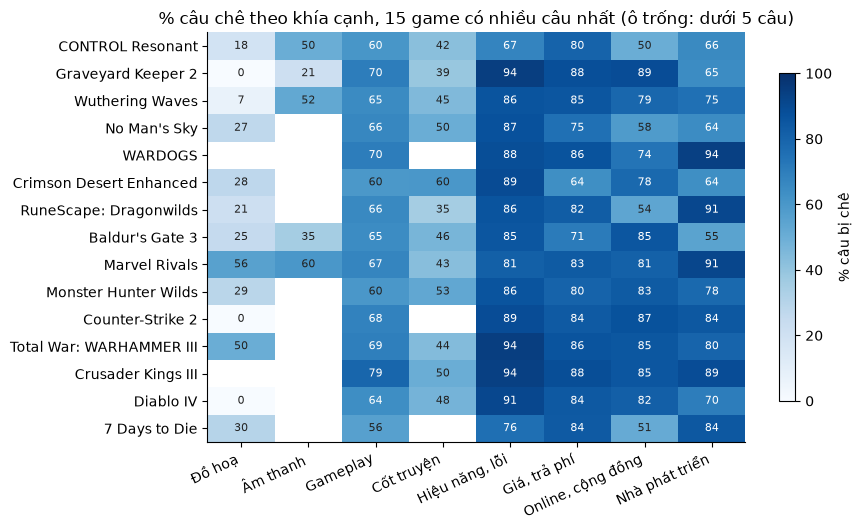

[16:09:03] tổng 100.0% | còn khoảng     0 phút | HOÀN TẤT toàn bộ notebook


In [11]:
def split_sents(t):
    return [p.strip() for p in re.split(r"(?<=[.!?])\s+|\n+", t) if len(p.split()) >= 3 and len(p) <= 600]
src = df.iloc[:300] if SMOKE else df
ROWS = [(g, s) for g, t in zip(src.game_name, src.text_clean) for s in split_sents(t)]
print("Số câu:", len(ROWS))
tien_do(f"Đầu ra theo game: nhận khía cạnh {len(ROWS)} câu")
PA = predict_with(ASP_MODELS["w"], 8, encode([r[1] for r in ROWS]))
HA = PA >= ASP_THR[0]
ii, jj = np.nonzero(HA)
tien_do(f"Đầu ra theo game: chấm khen/chê {len(ii)} cặp")
PP = predict_with(POL_MODELS["w"], 1, encode([ROWS[i][1] for i in ii], [ASPECT_WORD[ASPECTS[j]] for j in jj])).ravel()
out = pd.DataFrame({"game": [ROWS[i][0] for i in ii], "aspect": [ASPECTS[j] for j in jj], "p_khen": PP})
agg = out.groupby(["game", "aspect"]).agg(so_cau=("p_khen", "size"), pct_che=("p_khen", lambda s: round(100 * (s < .5).mean(), 1))).reset_index()
agg.to_csv(LABELS / ("aspect_by_game_smoke.csv" if SMOKE else "aspect_by_game.csv"), index=False, encoding="utf-8")
print("Tổng theo khía cạnh:"); display(out.groupby("aspect").agg(số_câu=("p_khen", "size"), pct_chê=("p_khen", lambda s: round(100 * (s < .5).mean(), 1))).rename(index=ASPECT_VI).sort_values("số_câu", ascending=False))

top = out.groupby("game").size().nlargest(15).index
tb = agg[agg.game.isin(top)].pivot(index="game", columns="aspect", values="pct_che").reindex(index=top, columns=ASPECTS)
nb = agg[agg.game.isin(top)].pivot(index="game", columns="aspect", values="so_cau").reindex(index=top, columns=ASPECTS).fillna(0)
masked = tb.where(nb >= 5)
fig, ax = plt.subplots(figsize=(9, 5.4))
im = ax.imshow(masked.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(8), [ASPECT_VI[a] for a in ASPECTS], rotation=25, ha="right"); ax.set_yticks(range(len(top)), [str(g)[:34] for g in top]); ax.grid(False)
for r in range(masked.shape[0]):
    for c in range(masked.shape[1]):
        v = masked.values[r, c]
        if not np.isnan(v):
            ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "#222")
fig.colorbar(im, label="% câu bị chê", shrink=.8); ax.set_title("% câu chê theo khía cạnh, 15 game có nhiều câu nhất (ô trống: dưới 5 câu)"); plt.tight_layout(); plt.show()
TRACK["done"] = TRACK["total"]; tien_do("HOÀN TẤT toàn bộ notebook")
json.dump(LOGS, open(LABELS / ("nhat_ky_train_smoke.json" if SMOKE else "nhat_ky_train.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1)

**Nhận xét** — Theo model, hiệu năng/lỗi, giá và nhà phát triển là ba khía cạnh bị chê nhiều nhất, trong khi đồ hoạ ít bị chê nhất. Do dữ liệu lấy cân bằng 50 khen + 50 chê mỗi game, các tỉ lệ này chỉ có ý nghĩa so sánh tương đối, không phản ánh tỉ lệ chê thực tế. Bảng dùng bản B với điểm yếu gán thừa khía cạnh, nên chủ yếu để minh hoạ dạng đầu ra.

## 8. Tổng kết

- **Khen/chê:** transformer vượt rõ model cũ ở cả hai kịch bản, đạt tiêu chí đề ra.
- **Nhận khía cạnh:** transformer chưa vượt từ khoá; nghi vấn chính là ngưỡng chọn trên tập dev khác phân phối với tập test.
- **Khen/chê theo khía cạnh:** mô hình theo cặp tốt nhất, nhưng câu trái cảm xúc vẫn khó.
- **Kế tiếp:** `aspect_model_run2.ipynb` kiểm tra đường cong học, ngưỡng, cách kết hợp từ khoá với transformer, và sửa rò rỉ ở tập dev.